In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score

print("All libraries imported successfully!")

All libraries imported successfully!


In [6]:
# Load the processeذd dataset

from pathlib import Path

filename = "processed_auto_mpg.csv"

file_path = Path(filename)

if not file_path.exists():
    folder = Path("/kaggle/input")
    file_path = next(folder.rglob(filename))

df = pd.read_csv(file_path)

print("Processed Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

Processed Dataset loaded successfully!
Dataset Shape: (392, 11)


,cylinders,displacement,horsepower,weight,acceleration,model year,power_to_weight,displacement_per_cylinder,weight_per_cylinder,displacement_squared,mpg
0,8,307.0,130.0,3504,12.0,70,0.037100,38.375,438.000,94249.0,18.0
1,8,350.0,165.0,3693,11.5,70,0.044679,43.750,461.625,122500.0,15.0
2,8,318.0,150.0,3436,11.0,70,0.043655,39.750,429.500,101124.0,18.0
3,8,304.0,150.0,3433,12.0,70,0.043694,38.000,429.125,92416.0,16.0
4,8,302.0,140.0,3449,10.5,70,0.040591,37.750,431.125,91204.0,17.0


In [7]:
# Select Input Features and Target

data = df.copy()

X = data.drop(columns=["mpg"]).values
y = data["mpg"].values

print("Dataset Shape:", data.shape)

print("\nInput Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nMissing Values:")
print(data.isnull().sum())

print("\nSelected Features:")
print(data.drop(columns=["mpg"]).columns.tolist())

display(data.head())

Dataset Shape: (392, 11)

Input Features Shape: (392, 10)
Target Shape: (392,)

Missing Values:
cylinders                    0
displacement                 0
horsepower                   0
weight                       0
acceleration                 0
model year                   0
power_to_weight              0
displacement_per_cylinder    0
weight_per_cylinder          0
displacement_squared         0
mpg                          0
dtype: int64

Selected Features:
['cylinders', 'displacement', 'horsepower', 'weight', 'acceleration', 'model year', 'power_to_weight', 'displacement_per_cylinder', 'weight_per_cylinder', 'displacement_squared']


,cylinders,displacement,horsepower,weight,acceleration,model year,power_to_weight,displacement_per_cylinder,weight_per_cylinder,displacement_squared,mpg
0,8,307.0,130.0,3504,12.0,70,0.037100,38.375,438.000,94249.0,18.0
1,8,350.0,165.0,3693,11.5,70,0.044679,43.750,461.625,122500.0,15.0
2,8,318.0,150.0,3436,11.0,70,0.043655,39.750,429.500,101124.0,18.0
3,8,304.0,150.0,3433,12.0,70,0.043694,38.000,429.125,92416.0,16.0
4,8,302.0,140.0,3449,10.5,70,0.040591,37.750,431.125,91204.0,17.0


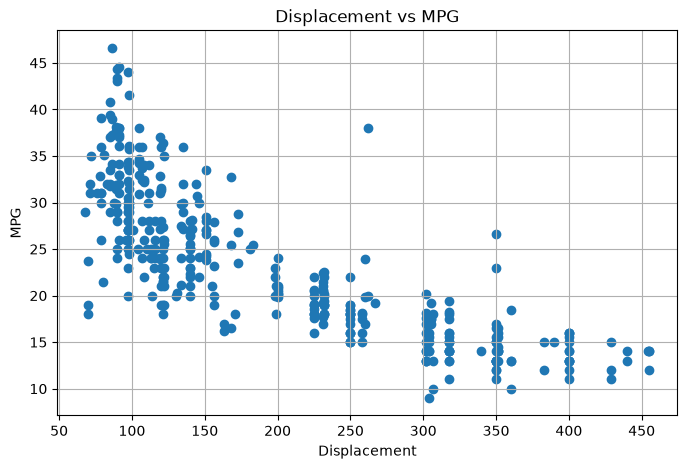

In [8]:
plt.figure(figsize=(8, 5))

plt.scatter(data["displacement"], data["mpg"])

plt.xlabel("Displacement")
plt.ylabel("MPG")
plt.title("Displacement vs MPG")

plt.grid(True)
plt.show()

In [9]:
# Split the dataset

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training Features Shape:", X_train.shape)
print("Testing Features Shape:", X_test.shape)

print("\nTraining Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)

Training Features Shape: (313, 10)
Testing Features Shape: (79, 10)

Training Target Shape: (313,)
Testing Target Shape: (79,)


In [10]:
# Feature Scaling

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Add bias column

X_train_final = np.column_stack([
    np.ones(len(X_train_scaled)),
    X_train_scaled
])

X_test_final = np.column_stack([
    np.ones(len(X_test_scaled)),
    X_test_scaled
])

print("Feature Scaling completed successfully!")

print("\nFinal Training Shape:", X_train_final.shape)
print("Final Testing Shape:", X_test_final.shape)

print("\nFirst 5 Training Samples:")
print(X_train_final[:5])

Feature Scaling completed successfully!

Final Training Shape: (313, 11)
Final Testing Shape: (79, 11)

First 5 Training Samples:
[[ 1.          0.30486156  0.28457757  0.14142863  0.75480297  1.1217589
   0.49452752 -0.72493759  0.45248146  0.58293575  0.03436432]
 [ 1.         -0.87318372 -0.53588042 -0.32949862 -0.49312922 -0.22893966
  -0.0572982   0.16237494  0.1625104   1.05657194 -0.60605257]
 [ 1.          0.30486156 -0.23665456 -0.19868549 -0.00252992 -0.37111846
  -0.33321105 -0.37549714 -0.59141435 -0.68274752 -0.40704341]
 [ 1.          1.48290683  1.18225513  1.18793363  1.3680521  -0.72656545
  -1.16094962  0.24575858  0.71345542 -0.44941204  1.07676277]
 [ 1.         -0.87318372 -1.05711255 -1.06205212 -1.32309939  0.30423083
   1.32226608 -0.10737411 -1.40333332 -1.02404418 -0.85796707]]


In [11]:
# Initialize Model Parameters
theta = np.zeros(X_train_final.shape[1])

# Learning Rate
learning_rate = 0.01

# Number of Epochs
epochs = 1000

# Momentum Parameter
beta = 0.9

# Cost Function (MSE)
def compute_cost(X, y, theta):
    predictions = X @ theta
    errors = predictions - y
    return np.mean(errors ** 2)

# Gradient Calculation
def compute_gradient(X, y, theta):
    predictions = X @ theta
    errors = predictions - y
    gradient = (2 / len(y)) * (X.T @ errors)
    return gradient

print("Initial Weights:", theta)
print("Initial Cost:", compute_cost(X_train_final, y_train, theta))

Initial Weights: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
Initial Cost: 620.0295846645367


In [12]:
# Initialize Parameters
theta_gd = np.zeros(X_train_final.shape[1])
velocity = np.zeros_like(theta_gd)

gd_loss_history = []

# Gradient Descent with Momentum
for epoch in range(epochs):

    # Calculate Gradient
    gradient = compute_gradient(
        X_train_final,
        y_train,
        theta_gd
    )

    # Update Momentum
    velocity = beta * velocity + gradient

    # Update Weights
    theta_gd = theta_gd - learning_rate * velocity

    # Calculate Loss
    loss = compute_cost(
        X_train_final,
        y_train,
        theta_gd
    )

    gd_loss_history.append(loss)

print("Training Completed!")
print("Final Weights:", theta_gd)
print("Final Training MSE:", gd_loss_history[-1])

Training Completed!
Final Weights: [23.59936102 -6.70600559 -2.21602299  1.84452398 -1.94611184 -0.39680024
  2.83965353 -1.91972006 -2.57250138 -2.15486336  5.83111424]
Final Training MSE: 8.353913678486752


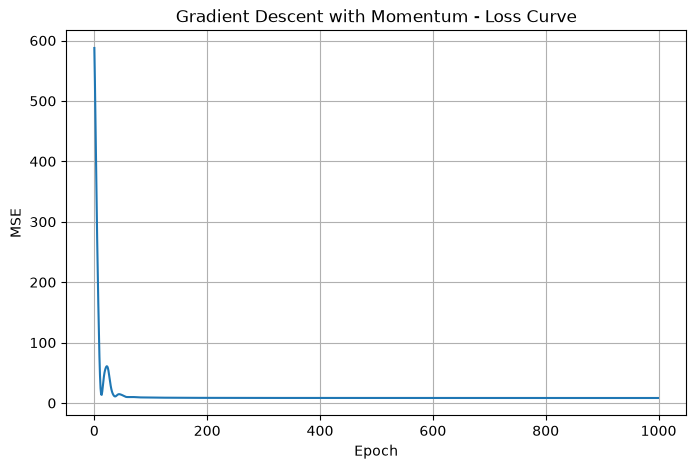

In [13]:
plt.figure(figsize=(8, 5))

plt.plot(gd_loss_history)

plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("Gradient Descent with Momentum - Loss Curve")

plt.grid(True)
plt.show()

In [14]:
from sklearn.metrics import mean_squared_error, r2_score

# Predictions on Test Data
y_pred = X_test_final @ theta_gd

# Evaluation Metrics
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Gradient Descent with Momentum Results")
print("---------------------------------------")
print("Test MSE:", mse)
print("Test RMSE:", rmse)
print("Test R2 Score:", r2)

Gradient Descent with Momentum Results
---------------------------------------
Test MSE: 8.915062573404164
Test RMSE: 2.9858102038482226
Test R2 Score: 0.8253338420623488


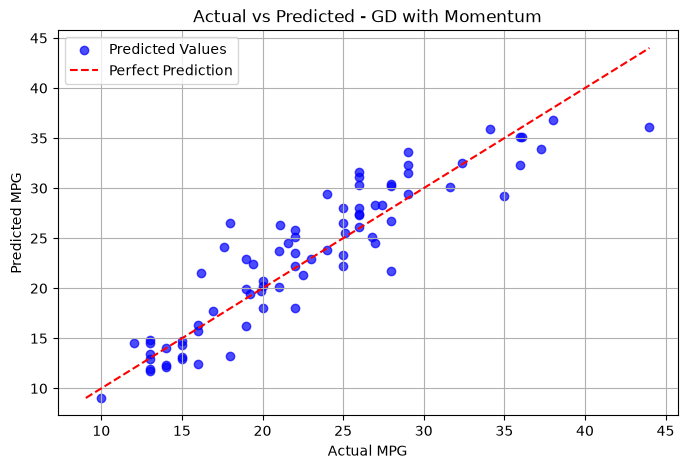

In [15]:
# Actual vs Predicted Values

plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred, color="blue",
            alpha=0.7, label="Predicted Values")

# Ideal prediction line
min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    color="red",
    linestyle="--",
    label="Perfect Prediction"
)

plt.xlabel("Actual MPG")
plt.ylabel("Predicted MPG")

plt.title("Actual vs Predicted - GD with Momentum")

plt.legend()
plt.grid(True)
plt.show()